<a href="https://colab.research.google.com/github/ViniciusCorreia-S/Angular/blob/origin/Bank_Marketing_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploração e Preparação dos Dados**

In [ ]:
#Importando Biblioteca Pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [ ]:
# Carregando a base de dados
dados = pd.read_csv("bank.csv")

In [ ]:
# Verificando quantidade de linhas e colunas
print("Dimensões:", dados.shape)

Dimensões: (11162, 17)


In [ ]:
# Exibindo os nomes das colunas
print(dados.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']


In [ ]:
# Exibindo as primeiras cinco linhas
dados.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [ ]:
# Verificando os tipos de dados
print(dados.dtypes)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object


In [ ]:
# Informações gerais sobre a base
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


# **Análise Exploratória De Dados (EDA)**

1. Estatísticas descritivas

In [ ]:
# Estatísticas descritivas das variáveis numéricas

dados.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.23,11.91,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.54,3225.41,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.66,8.42,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.99,347.13,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.51,2.72,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.33,108.76,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.83,2.29,0.0,0.0,0.0,1.00,58.0


In [ ]:
# Estatísticas das variáveis categóricas

dados.describe(include="object").T

,count,unique,top,freq
job,11162,12,management,2566
marital,11162,3,married,6351
education,11162,4,secondary,5476
default,11162,2,no,10994
housing,11162,2,no,5881
loan,11162,2,no,9702
contact,11162,3,cellular,8042
month,11162,12,may,2824
poutcome,11162,4,unknown,8326
deposit,11162,2,no,5873


In [ ]:
# Quantidade e percentual de clientes que aderiram ao depósito

resumo = pd.DataFrame({
    "Quantidade": dados["deposit"].value_counts(),
    "Percentual (%)": (
        dados["deposit"].value_counts(normalize=True) * 100
    ).round(2)
})

display(resumo)

,Quantidade,Percentual (%)
deposit,,
no,5873,52.62
yes,5289,47.38


2. Identificação de Valores Ausentes

In [ ]:
# Identificação de valores ausentes

ausentes = pd.DataFrame({
    "Quantidade": dados.isnull().sum(),
    "Percentual (%)": (dados.isnull().mean() * 100).round(2)
})

display(ausentes)

print("Total de valores ausentes:", dados.isnull().sum().sum())

,Quantidade,Percentual (%)
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


Total de valores ausentes: 0


In [ ]:
# Identificar valores desconhecidos nas variáveis categóricas

desconhecidos = []

for coluna in dados.select_dtypes(include="object").columns:
    quantidade = (
        dados[coluna]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    if quantidade > 0:
        desconhecidos.append({
            "Variável": coluna,
            "Quantidade de unknown": quantidade
        })

if desconhecidos:
    display(pd.DataFrame(desconhecidos))
else:
    print("Nenhuma categoria unknown encontrada.")

,Variável,Quantidade de unknown
0,job,70
1,education,497
2,contact,2346
3,poutcome,8326


3. Identificação de inconsistências

In [ ]:
# 3. Identificação de registros duplicados

duplicados = dados.duplicated().sum()

print("Registros duplicados:", duplicados)

# Exibir os registros duplicados, se existirem
display(dados[dados.duplicated(keep=False)].head(20))

Registros duplicados: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit


In [ ]:
# Verificar valores fora dos intervalos esperados

inconsistencias = {
    "Idade negativa ou acima de 120":
        ((dados["age"] < 0) | (dados["age"] > 120)).sum(),

    "Dia fora do intervalo de 1 a 31":
        ((dados["day"] < 1) | (dados["day"] > 31)).sum(),

    "Campanha com menos de 1 contato":
        (dados["campaign"] < 1).sum(),

    "Duração negativa":
        (dados["duration"] < 0).sum(),

    "pdays menor que -1":
        (dados["pdays"] < -1).sum(),

    "Contatos anteriores negativos":
        (dados["previous"] < 0).sum()
}

display(pd.DataFrame({
    "Verificação": inconsistencias.keys(),
    "Quantidade": inconsistencias.values()
}))

,Verificação,Quantidade
0,Idade negativa ou acima de 120,0
1,Dia fora do intervalo de 1 a 31,0
2,Campanha com menos de 1 contato,0
3,Duração negativa,0
4,pdays menor que -1,0
5,Contatos anteriores negativos,0


4. Visualizações gráficas relevantes

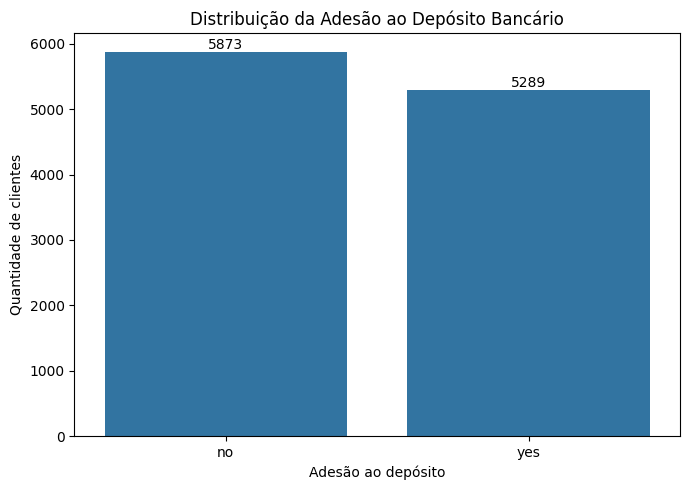

In [ ]:
# Variável-alvo deposit

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=dados, x="deposit", order=["no", "yes"])

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribuição da Adesão ao Depósito Bancário")
plt.xlabel("Adesão ao depósito")
plt.ylabel("Quantidade de clientes")

plt.tight_layout()
plt.show()

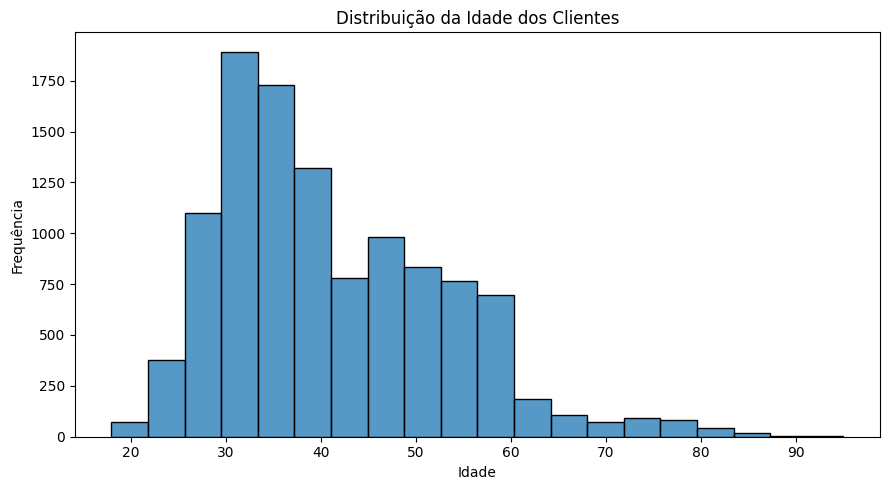

In [ ]:
# Histograma da idade

plt.figure(figsize=(9, 5))

sns.histplot(data=dados, x="age", bins=20)

plt.title("Distribuição da Idade dos Clientes")
plt.xlabel("Idade")
plt.ylabel("Frequência")

plt.tight_layout()
plt.show()

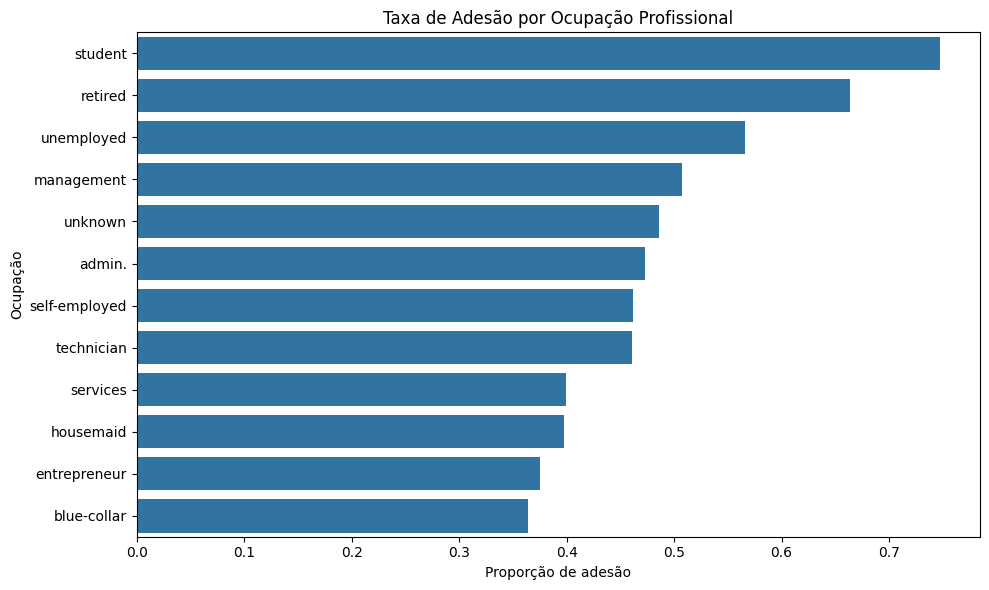

In [ ]:
# Taxa de adesão por ocupação

dados_grafico = dados.copy()

dados_grafico["aderiu"] = (
    dados_grafico["deposit"].str.lower() == "yes"
)

taxa_ocupacao = (
    dados_grafico.groupby("job")["aderiu"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=taxa_ocupacao.values,
    y=taxa_ocupacao.index
)

plt.title("Taxa de Adesão por Ocupação Profissional")
plt.xlabel("Proporção de adesão")
plt.ylabel("Ocupação")

plt.tight_layout()
plt.show()

# **Separação dos Dados em Treinamento e Teste**

1. Separar as variáveis

In [ ]:
# X contém as informações usadas para fazer previsões
X = dados.drop(columns=["deposit", "duration"])

# y contém o resultado que queremos prever
y = dados["deposit"].map({"no": 0, "yes": 1})

2. Dividir os dados

In [ ]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados para treinamento:", X_treino.shape[0])
print("Dados para teste:", X_teste.shape[0])

Dados para treinamento: 8929
Dados para teste: 2233


# **Pré-processamento dos Dados**

1. Tratamento de valores ausentes e engenharia de atributos

In [ ]:
# Verificar valores ausentes
print("Total de valores ausentes:", dados.isnull().sum().sum())

Total de valores ausentes: 0


In [ ]:
# Preencher valores ausentes, se existirem
for coluna in dados.select_dtypes(include="number"):
    dados[coluna] = dados[coluna].fillna(dados[coluna].median())

for coluna in dados.select_dtypes(include="object"):
    if dados[coluna].isnull().any():
        dados[coluna] = dados[coluna].fillna(dados[coluna].mode()[0])

# Criar atributo para indicar se houve contato anterior
dados["contato_anterior"] = (dados["pdays"] != -1).astype(int)

print("Valores ausentes:", dados.isnull().sum().sum())
display(dados.head())

Valores ausentes: 0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,contato_anterior
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes,0
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes,0
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes,0
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes,0
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes,0


2. Padronizar as variáveis numéricas

In [ ]:
from sklearn.preprocessing import StandardScaler

colunas = ["age", "balance", "day", "campaign", "previous"]

escalador = StandardScaler()

X_treino[colunas] = escalador.fit_transform(X_treino[colunas])
X_teste[colunas] = escalador.transform(X_teste[colunas])

print("Padronização concluída!")

Padronização concluída!


3. Codificar as variáveis categóricas

In [ ]:
# Transformar categorias em números
X_treino = pd.get_dummies(X_treino, dtype=int)
X_teste = pd.get_dummies(X_teste, dtype=int)

# Manter as mesmas colunas nos dois conjuntos
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0)

print("Codificação concluída!")

Codificação concluída!


## Conferir o resultado

In [ ]:
print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

print("Valores ausentes no treinamento:", X_treino.isnull().sum().sum())
print("Valores ausentes no teste:", X_teste.isnull().sum().sum())

display(X_treino.head())

Treinamento: (8929, 50)
Teste: (2233, 50)
Valores ausentes no treinamento: 0
Valores ausentes no teste: 0


,age,balance,day,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
8644,0.412051,-0.321431,1.817208,0.178481,-1,-0.355931,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2632,0.412051,0.359538,-1.504820,-0.540031,94,3.075684,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
3056,-1.356310,-0.451508,-0.555669,-0.540031,91,0.073021,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1080,0.159428,0.606919,0.630770,0.178481,-1,-0.355931,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4006,-0.345818,-0.425291,0.868057,-0.180775,-1,-0.355931,0,1,0,0,...,0,0,0,0,0,1,0,0,0,1


# **Random Forest**

1. Treinar Modelo

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Cria o modelo
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Treina o modelo
modelo_rf.fit(X_treino, y_treino)

# Faz previsões
previsoes_rf = modelo_rf.predict(X_teste)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


2. Avaliar o Random Forest

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("RESULTADOS - RANDOM FOREST")

print("Acurácia:", round(accuracy_score(y_teste, previsoes_rf), 3))
print("Precisão:", round(precision_score(y_teste, previsoes_rf, zero_division=0), 3))
print("Recall:", round(recall_score(y_teste, previsoes_rf, zero_division=0), 3))
print("F1-score:", round(f1_score(y_teste, previsoes_rf, zero_division=0), 3))

RESULTADOS - RANDOM FOREST
Acurácia: 0.723
Precisão: 0.748
Recall: 0.627
F1-score: 0.682


3. Visualizar a Matriz de Confusão

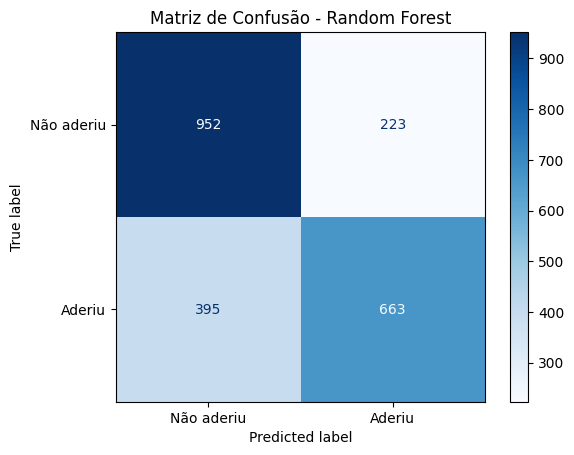

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes_rf,
    display_labels=["Não aderiu", "Aderiu"],
    cmap="Blues"
)

plt.title("Matriz de Confusão - Random Forest")
plt.show()

# **Regressão Logística**

1. Treinar Modelo

In [ ]:
from sklearn.linear_model import LogisticRegression

# Cria o modelo
modelo_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Treina o modelo
modelo_lr.fit(X_treino, y_treino)

# Faz previsões
previsoes_lr = modelo_lr.predict(X_teste)

print("Regressão Logística treinada com sucesso!")

Regressão Logística treinada com sucesso!


2. Avaliar Regressão Logística

In [ ]:
print("RESULTADOS - REGRESSÃO LOGÍSTICA")

print("Acurácia:", round(accuracy_score(y_teste, previsoes_lr), 3))
print("Precisão:", round(precision_score(y_teste, previsoes_lr, zero_division=0), 3))
print("Recall:", round(recall_score(y_teste, previsoes_lr, zero_division=0), 3))
print("F1-score:", round(f1_score(y_teste, previsoes_lr, zero_division=0), 3))

RESULTADOS - REGRESSÃO LOGÍSTICA
Acurácia: 0.695
Precisão: 0.732
Recall: 0.561
F1-score: 0.635


3. Visualizar a Matriz de Confusão

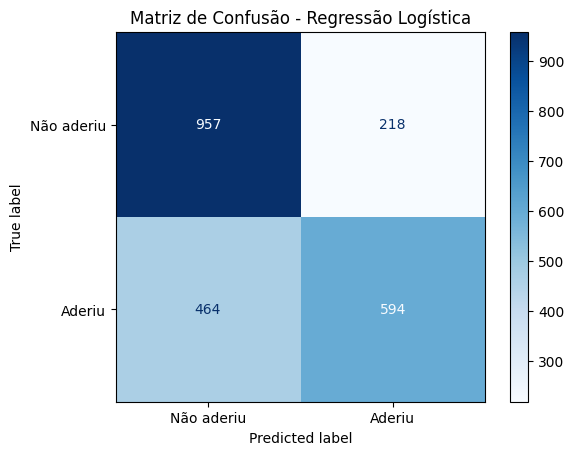

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes_lr,
    display_labels=["Não aderiu", "Aderiu"],
    cmap="Blues"
)

plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

### **Comparar os Modelos**

In [ ]:
resultados = pd.DataFrame({
    "Modelo": ["Random Forest", "Regressão Logística"],
    "Acurácia": [
        accuracy_score(y_teste, previsoes_rf),
        accuracy_score(y_teste, previsoes_lr)
    ],
    "Precisão": [
        precision_score(y_teste, previsoes_rf, zero_division=0),
        precision_score(y_teste, previsoes_lr, zero_division=0)
    ],
    "Recall": [
        recall_score(y_teste, previsoes_rf, zero_division=0),
        recall_score(y_teste, previsoes_lr, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_teste, previsoes_rf, zero_division=0),
        f1_score(y_teste, previsoes_lr, zero_division=0)
    ]
})

display(resultados.round(3))

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Random Forest,0.723,0.748,0.627,0.682
1,Regressão Logística,0.695,0.732,0.561,0.635


# **Validação cruzada — Stratified K-Fold**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Criar a validação cruzada com 5 partições
validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Criar o modelo escolhido anteriormente
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Avaliar o modelo por validação cruzada
resultados_cv = cross_validate(
    modelo_rf,
    X_treino,
    y_treino,
    cv=validacao,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar a média das métricas nas 5 partições
resultado_final = pd.DataFrame({
    "Métrica": ["Acurácia", "Precisão", "Recall", "F1-score"],
    "Média": [
        resultados_cv["test_accuracy"].mean(),
        resultados_cv["test_precision"].mean(),
        resultados_cv["test_recall"].mean(),
        resultados_cv["test_f1"].mean()
    ],
    "Desvio padrão": [
        resultados_cv["test_accuracy"].std(),
        resultados_cv["test_precision"].std(),
        resultados_cv["test_recall"].std(),
        resultados_cv["test_f1"].std()
    ]
})

display(resultado_final.round(3))

,Métrica,Média,Desvio padrão
0,Acurácia,0.724,0.002
1,Precisão,0.740,0.010
2,Recall,0.646,0.019
3,F1-score,0.690,0.007


## **RandomizedSearchCV para o Random Forest**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

parametros = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

busca = RandomizedSearchCV(
    modelo_rf,
    param_distributions=parametros,
    n_iter=10,
    cv=validacao,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

busca.fit(X_treino, y_treino)

print("Melhores hiperparâmetros:", busca.best_params_)
print("Melhor F1-score:", round(busca.best_score_, 3))

# Modelo ajustado
modelo_rf = busca.best_estimator_

Melhores hiperparâmetros: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Melhor F1-score: 0.697
